# Predicting answer correctness with a mixed model

The same question as `../overview.ipynb`: from how a participant looks at the question and the
four answers, can we tell whether they will choose the correct one? There the model is a logistic
regression, in which every trial counts as independent of every other. Here it is a generalised
linear mixed model (GLMM): the same regression with a random intercept per participant and per
test item,

```
is_correct ~ 1 + <features> + (1 | participant_id) + (1 | text_id_with_q)
```

The intercepts let each participant be more or less accurate in general, and each item (a
paragraph with one of its three questions) easier or harder, without the features having to
explain it. Everything else is the logistic regression's: the features are prepared by the same
code (every missing value filled with 0 and counted, then standardised), trials are weighted so
that correct and wrong answers count equally, a probability above 0.5 is predicted correct, and
the folds, scores and figures are made by the same functions, given `model_builder`.

Three differences to keep in mind:

* **No L2 penalty.** The logistic regression has sklearn's default (C = 1). On this many trials it
  is small, but it is not nothing.
* **The class weights act on the variances too.** In a mixed model they also enlarge the
  estimated spread of the random intercepts, and the standard errors come from a weighted
  likelihood. Section 3 puts the unweighted fit beside it.
* **Two ways to score a held-out trial.** `glmm_fixed` sets every random intercept to 0, scoring
  each trial as if its participant and item were average. `glmm_known_levels` adds a participant's
  or item's estimated intercept when it was in the training data. They differ only where one of
  the two was seen: on a new paragraph the participant is known, on a new participant the item is.
  With both new they are identical.

What does not carry over from the logistic regression: the coefficient intervals are Wald
intervals from the model's own standard errors, not the participant bootstrap (thousands of
mixed-model fits); a model per participant (`../person_variance/`) has no meaning here, since a
single participant has no participant intercept to vary; and random slopes cannot be fitted in
MixedModels (`modeling/models/glmm_model.py` says why).

It needs Julia: run `src/vendor/julia_integration/julia_test.ipynb` once first. One fit takes
10 to 20 seconds, and the notebook fits about a hundred times, so it runs for about fifteen
minutes.
This notebook only shows; it saves nothing.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import src.config.columns as Con
from src.config.datasets import dataset, HUNTERS_REFOLDED_DIR, GATHERERS_REFOLDED_DIR
from src.features.build import load_model_ready, load_model_input
from src.modeling.feature_sets import SELECT_1_COLS, LAST_CONFIRM_COMPACT, load_feature_sets
from src.modeling.models.logreg_model import TrialLevelLogRegModel, imputed_cell_counts
from src.modeling.models.glmm_model import TrialLevelJuliaGLMERModel   # starts Julia
from src.modeling.crossval import run_cross_validation_on_combined_folds
from src.modeling.evaluate import collect_logreg_coef_summaries
from src.analyses.correctness_prediction.run import (
    build_train_test_trial_dfs, run_full_features_correctness_bundle,
)
from src.analyses.correctness_prediction.comparison import TESTS, run_model_comparison
from src.analyses.correctness_prediction.plots.coefficients import plot_coef_summary_barh
from src.analyses.correctness_prediction.plots.cv_comparison import plot_cv_metric_by_regime_pretty
from src.analyses.correctness_prediction.plots.feature_ranks import plot_feature_correlation_heatmap
from src.analyses.correctness_prediction.plots.model_comparison import plot_model_comparison
from src.analyses.correctness_prediction.plots.probabilities import plot_predicted_probability_hist
from src.analyses.correctness_prediction.mixed_model.run import run_glmm_fit_all, variance_summary
from src.analyses.correctness_prediction.mixed_model.plots import (
    plot_coefficient_comparison, plot_random_effects_distribution,
)

trial_df = load_model_ready()                             # one row per trial, features + is_correct
word_df = load_model_input(dataset("l1"), verbose=False)  # one row per word; the folds need it

FEATURE_SETS = {
    "select_1": SELECT_1_COLS,                                          # ten attention features
    "select_1_plus_last_confirm": SELECT_1_COLS + LAST_CONFIRM_COMPACT,  # + where the last look landed
}
HEADLINE = FEATURE_SETS["select_1_plus_last_confirm"]
TEXT = Con.TEXT_ID_WITH_Q_COLUMN   # the item: a paragraph and the question asked about it


def glmm(predict_with="fixed", **kwargs):
    # A maker of unfitted mixed models, for the functions that take `model_builder`.
    return lambda: TrialLevelJuliaGLMERModel(
        name=f"glmm_{predict_with}", predict_with=predict_with, **kwargs,
    )

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


## 1. The trial table, the features, and the two grouping levels

The same trial table and the same two feature sets as the logistic regression (its notebook
describes them): ten attention features (`select_1`), and the same ten plus where the last look
before confirming landed (`select_1_plus_last_confirm`, the paper's best model).

What is new is the grouping. Every participant answered 53 or 54 questions and every item was
answered by 19 or 20 participants, so both can carry a random intercept. The accuracy columns show
how far apart participants and items are before any eye movement is considered: that spread is
what the random intercepts take up.

In [2]:
print(f"{len(trial_df):,} trials, {trial_df[Con.IS_CORRECT_COLUMN].mean():.1%} answered correctly")


def level_table(col):
    per_level = trial_df.groupby(col)[Con.IS_CORRECT_COLUMN]
    accuracy = per_level.mean()
    return {
        "levels": per_level.ngroups,
        "trials per level, min": per_level.size().min(),
        "trials per level, max": per_level.size().max(),
        "accuracy, 10th percentile": accuracy.quantile(0.1),
        "accuracy, median": accuracy.median(),
        "accuracy, 90th percentile": accuracy.quantile(0.9),
    }


pd.DataFrame({"participant": level_table(Con.PARTICIPANT_ID), "item": level_table(TEXT)}).T.round(3)

19,436 trials, 84.1% answered correctly


,levels,"trials per level, min","trials per level, max","accuracy, 10th percentile","accuracy, median","accuracy, 90th percentile"
participant,360.0,53.0,54.0,0.722,0.852,0.944
item,972.0,19.0,20.0,0.650,0.900,1.000


As in the logistic regression, the pupil feature is missing where the correct answer was never
looked at, and those cells are filled with 0: an assumption, not a measurement. The same cells,
counted the same way:

In [3]:
imputed_cell_counts(trial_df, HEADLINE)

mean_max_fix_pupil_size_z__correct    253
dtype: int64

## 2. Cross-validated accuracy, against the logistic regression
*`modeling.crossval.run_cross_validation_on_combined_folds`*

The paper's ten folds, pooled over hunters and gatherers. For each feature set, three models are
fitted in each fold on the same training trials and scored on the same held-out ones: the logistic
regression (the paper's numbers), and the mixed model scored both ways. The table gives the mean
balanced accuracy over the folds, weighted by how many trials each fold scored; chance is 0.5. The
held-out trials are a new paragraph read by a training participant (`new_item`), a new participant
reading a training paragraph (`new_subject`), or both new.

In [4]:
# The fold files name paragraphs by `text_id`, which the trial table does not carry; the
# word-level frame does. One row per trial is all the fold matching needs.
trial_ids = word_df[[Con.PARTICIPANT_ID, Con.TRIAL_ID, Con.TEXT_ID_COLUMN]].drop_duplicates()
assert len(trial_ids) == len(trial_df), "expected exactly one paragraph per trial"

fitted = {}   # every mixed model the cross-validation fits, kept for the fit report below


def recorded(name, predict_with):
    def build():
        model = TrialLevelJuliaGLMERModel(name=name, predict_with=predict_with)
        fitted.setdefault(name, []).append(model)
        return model
    return build


MODELS, COLS = {}, {}
for set_name, cols in FEATURE_SETS.items():
    MODELS[f"{set_name} | logreg"] = TrialLevelLogRegModel
    for predict_with in ["fixed", "known_levels"]:
        name = f"{set_name} | glmm_{predict_with}"
        MODELS[name] = recorded(name, predict_with)
    COLS.update({name: cols for name in MODELS if name.startswith(set_name + " |")})

cv_out = run_cross_validation_on_combined_folds(
    trial_ids,
    fold_dirs=[HUNTERS_REFOLDED_DIR, GATHERERS_REFOLDED_DIR],  # both groups' folds, pooled
    model_builders=MODELS,
    feature_cols_by_model=COLS,
    target_col=Con.IS_CORRECT_COLUMN,
    n_folds=10,
    trial_df=trial_df,
)

(cv_out.summary_by_novelty_df
    .pivot(index="model", columns="novelty", values="mean_balanced_accuracy")
    .loc[list(MODELS), ["new_item", "new_subject", "both"]]
    .round(3))

novelty,new_item,new_subject,both
model,,,
select_1 | logreg,0.790,0.789,0.795
select_1 | glmm_fixed,0.760,0.759,0.750
select_1 | glmm_known_levels,0.773,0.795,0.750
select_1_plus_last_confirm | logreg,0.827,0.829,0.835
select_1_plus_last_confirm | glmm_fixed,0.818,0.816,0.814
select_1_plus_last_confirm | glmm_known_levels,0.823,0.834,0.814


**Did every fit converge?** One row per feature set and fold. The two mixed-model rows of a fold
are the same fit (same training trials, same weights) scored two ways, which the last line checks.
`sd_*` are the estimated standard deviations of the random intercepts, on the log-odds scale.

In [5]:
rows = []
for set_name in FEATURE_SETS:
    fixed_fits = fitted[f"{set_name} | glmm_fixed"]
    known_fits = fitted[f"{set_name} | glmm_known_levels"]
    for fold, (a, b) in enumerate(zip(fixed_fits, known_fits)):
        sd = a.get_variance_components().set_index("group")["sd"]
        rows.append({
            "feature set": set_name, "fold": fold, "n_train": a.n_train_,
            "optimizer": a.optimizer_returnvalue_, "converged": a.converged_,
            "singular": a.is_singular_, "sd_participant": sd[Con.PARTICIPANT_ID],
            "sd_item": sd[TEXT],
            "same fit both ways": bool(np.allclose(a.coef_, b.coef_) and a.intercept_ == b.intercept_),
        })
fit_report = pd.DataFrame(rows)
print(f"{int(fit_report['converged'].sum())} of {len(fit_report)} fits converged, "
      f"{int(fit_report['singular'].sum())} singular, "
      f"{int(fit_report['same fit both ways'].sum())} shared by both scorings")
fit_report.round(3)

20 of 20 fits converged, 0 singular, 20 shared by both scorings


,feature set,fold,n_train,optimizer,converged,singular,sd_participant,sd_item,same fit both ways
0,select_1,0,11711,FTOL_REACHED,True,False,0.903,1.518,True
1,select_1,1,11904,FTOL_REACHED,True,False,0.959,1.598,True
2,select_1,2,12190,FTOL_REACHED,True,False,0.962,1.572,True
3,select_1,3,12477,FTOL_REACHED,True,False,0.985,1.591,True
4,select_1,4,12861,FTOL_REACHED,True,False,0.967,1.656,True
5,select_1,5,13054,FTOL_REACHED,True,False,0.952,1.788,True
6,select_1,6,13054,FTOL_REACHED,True,False,1.004,1.733,True
7,select_1,7,12573,FTOL_REACHED,True,False,1.055,1.693,True
8,select_1,8,12380,FTOL_REACHED,True,False,0.968,1.678,True
9,select_1,9,12188,FTOL_REACHED,True,False,0.906,1.546,True


The same scores split into the six held-out regimes, for each mixed model. Bars are the mean over
folds; the error bars are a 95% interval across folds, narrower than the real uncertainty because
the folds share most of their training data. The "both new" bars are the smallest samples, so they
move the most.

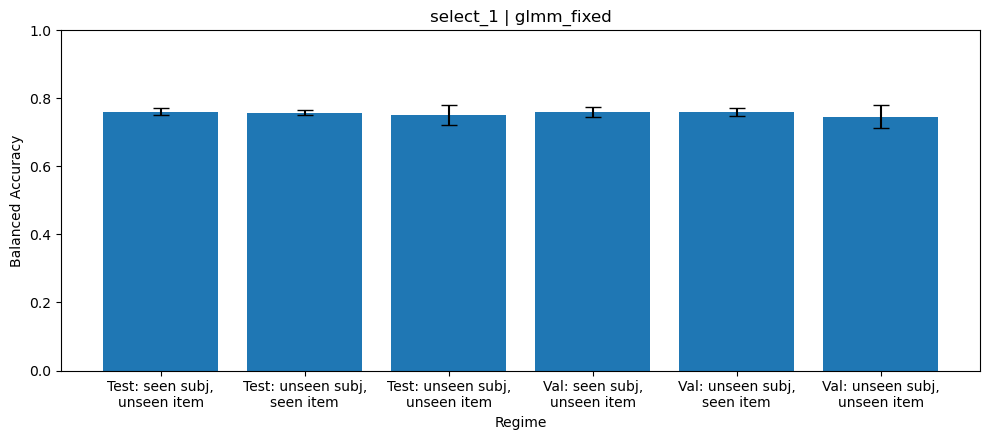

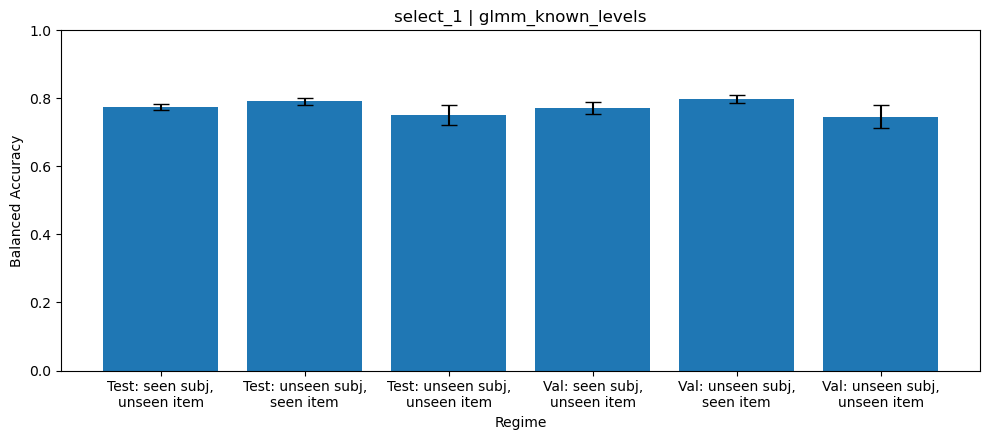

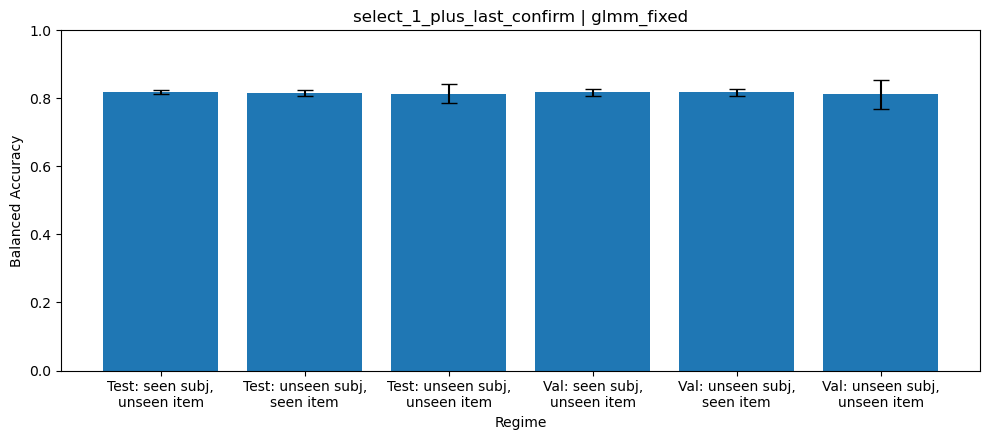

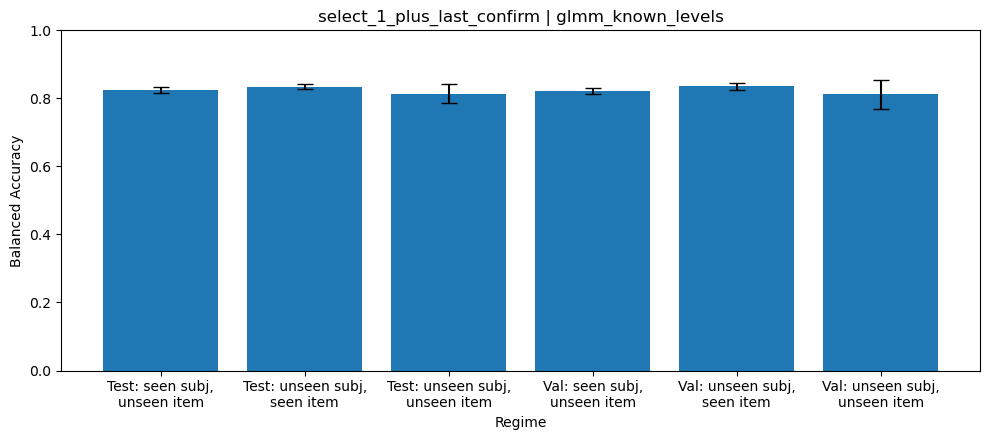

In [6]:
for name in MODELS:
    if "glmm" in name:
        _, fig, ax = plot_cv_metric_by_regime_pretty(cv_out, model_name=name, figsize=(10, 4.5))
        ax.set_title(name)
        plt.show()

### Comparing models, on Study 1 and Study 2
*`comparison.run_model_comparison`, `plots.model_comparison.plot_model_comparison`*

As in the logistic-regression notebook: every feature set saved in `configs/feature_sets/`, each
fitted as a mixed model and scored twice. On Study 1 by the same ten-fold cross-validation, one
panel per kind of held-out trial and one for their average. On Study 2 (KnowQA) after one fit on
every Study 1 trial, one panel per knowledge regime and one for all of them together; Study 2 is one
fit and one test set, so its bars have no interval. Every Study 2 participant is new, so the mixed
model is scored on its fixed effects here (`glmm_fixed`). The bars start at chance (0.5). This is
the slow cell: about two minutes per feature set.

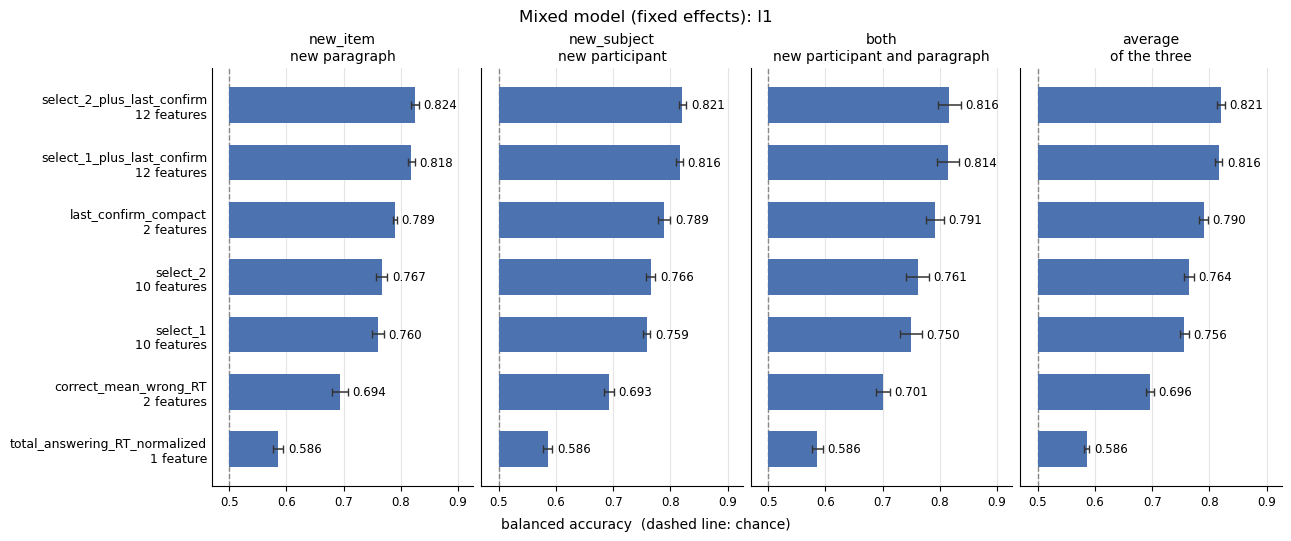

test,new_item,new_subject,both,average
model,,,,
correct_mean_wrong_RT,0.694,0.693,0.701,0.696
last_confirm_compact,0.789,0.789,0.791,0.790
select_1,0.760,0.759,0.750,0.756
select_1_plus_last_confirm,0.818,0.816,0.814,0.816
select_2,0.767,0.766,0.761,0.764
select_2_plus_last_confirm,0.824,0.821,0.816,0.821
total_answering_RT_normalized,0.586,0.586,0.586,0.586


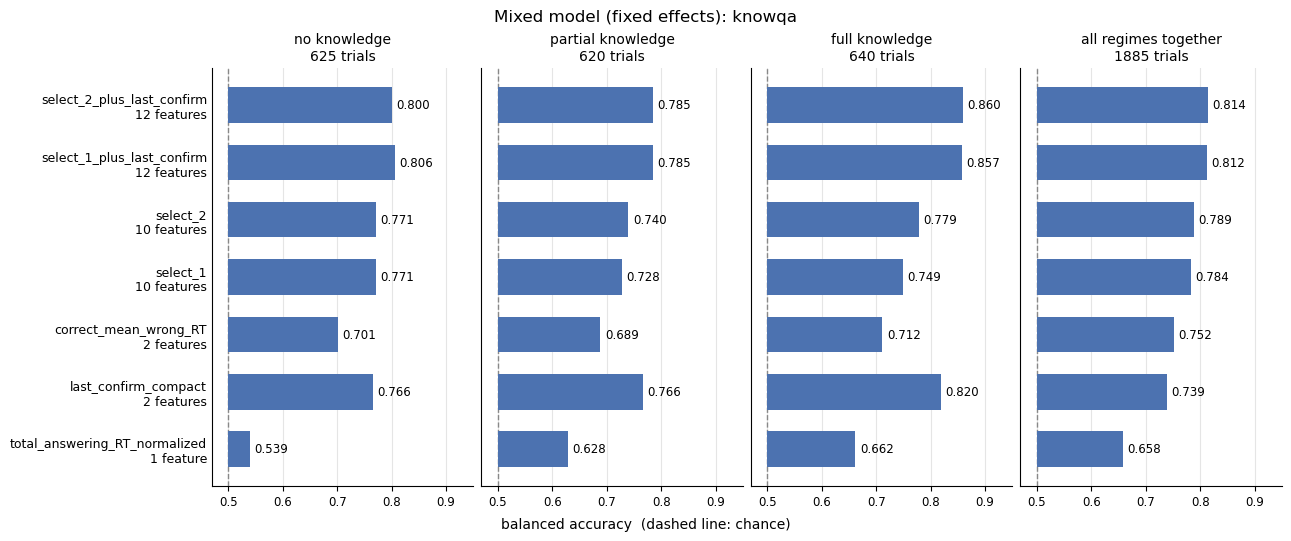

test,no knowledge,partial knowledge,full knowledge,all
model,,,,
correct_mean_wrong_RT,0.701,0.689,0.712,0.752
last_confirm_compact,0.766,0.766,0.820,0.739
select_1,0.771,0.728,0.749,0.784
select_1_plus_last_confirm,0.806,0.785,0.857,0.812
select_2,0.771,0.740,0.779,0.789
select_2_plus_last_confirm,0.800,0.785,0.860,0.814
total_answering_RT_normalized,0.539,0.628,0.662,0.658


In [7]:
glmm_comparison = run_model_comparison(
    word_df, load_feature_sets(), trial_df=trial_df, model_builder=glmm("fixed"), verbose=False,
)

scores = glmm_comparison["scores"]
for ds in TESTS:   # "l1", then "knowqa"
    plot_model_comparison(glmm_comparison, dataset=ds, title=f"Mixed model (fixed effects): {ds}")
    plt.show()
    display(scores[scores["dataset"] == ds]
            .pivot(index="model", columns="test", values="balanced_accuracy")[TESTS[ds]]
            .round(3))

The headline model three ways, side by side: the logistic regression, and the mixed model scored on
its fixed effects and with the known intercepts. On Study 2 the participants are all new, but every
item is also a Study 1 item, so `glmm_known_levels` adds the item's Study 1 intercept (how hard it
was for Study 1 readers). `../knowledge_regimes` and `knowledge_regimes.ipynb` beside this notebook
look at Study 2 in detail.

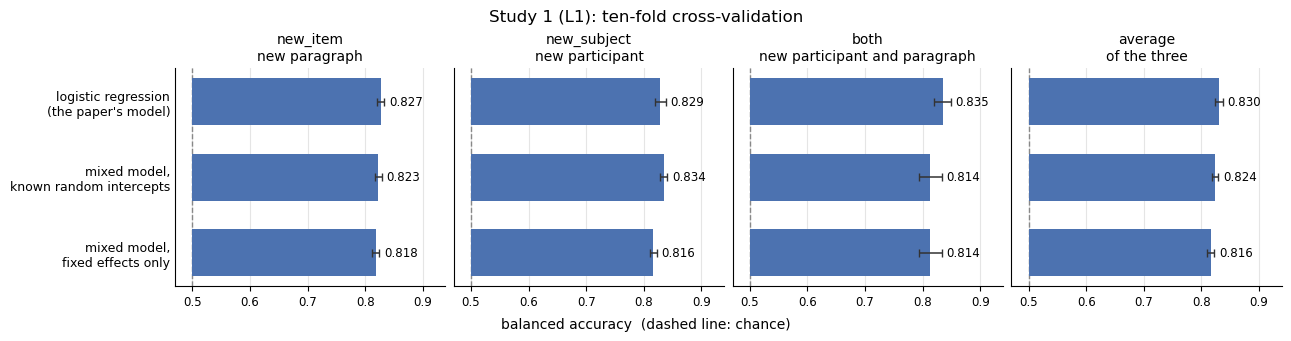

test,new_item,new_subject,both,average
model,,,,
glmm_fixed,0.818,0.816,0.814,0.816
glmm_known_levels,0.823,0.834,0.814,0.824
logreg,0.827,0.829,0.835,0.830


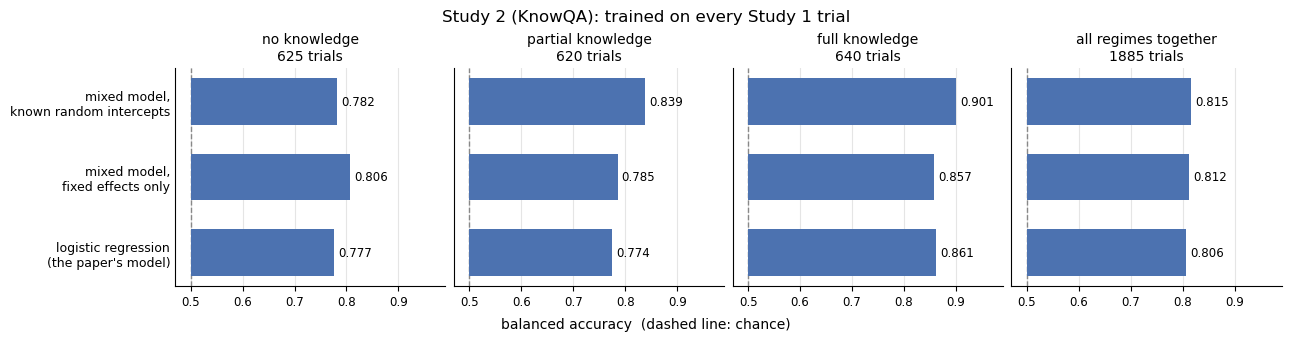

test,no knowledge,partial knowledge,full knowledge,all
model,,,,
glmm_fixed,0.806,0.785,0.857,0.812
glmm_known_levels,0.782,0.839,0.901,0.815
logreg,0.777,0.774,0.861,0.806


In [8]:
headline = {"select_1_plus_last_confirm": HEADLINE}
side_by_side = {
    "logreg": run_model_comparison(word_df, headline, trial_df=trial_df, verbose=False),
    "glmm_fixed": {k: v[v["model"] == "select_1_plus_last_confirm"] for k, v in glmm_comparison.items()},
    "glmm_known_levels": run_model_comparison(
        word_df, headline, trial_df=trial_df, model_builder=glmm("known_levels"), verbose=False,
    ),
}
comparison = {
    part: pd.concat([run[part].assign(model=name) for name, run in side_by_side.items()],
                    ignore_index=True)
    for part in ("scores", "folds")
}
LABELS = {
    "logreg": "logistic regression\n(the paper's model)",
    "glmm_fixed": "mixed model,\nfixed effects only",
    "glmm_known_levels": "mixed model,\nknown random intercepts",
}
for ds in TESTS:
    plot_model_comparison(comparison, dataset=ds, labels=LABELS)
    plt.show()
    display(comparison["scores"][comparison["scores"]["dataset"] == ds]
            .pivot(index="model", columns="test", values="balanced_accuracy")[TESTS[ds]].round(3))

## 3. The coefficients: one fit on all trials
*`modeling.evaluate.collect_logreg_coef_summaries`*

One fit on all 19,436 trials per feature set, as in the logistic-regression notebook. Features are
standardised, so each coefficient is the change in log-odds of a correct answer for one standard
deviation of the feature, with the participant and the item held fixed; positive means "more of
this, more likely correct". The intervals are Wald intervals from the model's own standard errors,
which account for trials sharing a participant or an item through the random intercepts.

In [9]:
coef_by_set = collect_logreg_coef_summaries(
    trial_df,
    FEATURE_SETS,
    model_builder=glmm("fixed"),
    ci_method="wald",        # the mixed model's own standard errors
    ci_cluster="cluster",    # the grouping is in the model, as the random intercepts
)

coef_by_set["select_1_plus_last_confirm"][
    ["feature", "coef", "ci_low", "ci_high", "odds_ratio", "sig_ci", "p_value"]
].round(3)

,feature,coef,ci_low,ci_high,odds_ratio,sig_ci,p_value
0,area_dwell_proportion__correct,1.474,1.375,1.573,4.367,True,0.000
1,last_before_confirm_correct,1.454,1.388,1.521,4.281,True,0.000
2,mean_fixations_count__wrong_mean,-0.568,-0.670,-0.466,0.567,True,0.000
3,num_label_visits__contrast,0.372,0.263,0.482,1.451,True,0.000
4,num_label_visits__correct,-0.288,-0.410,-0.165,0.750,True,0.000
5,has_xyx,-0.269,-0.324,-0.214,0.764,True,0.000
6,area_dwell_proportion__question,0.234,0.161,0.306,1.263,True,0.000
7,mean_max_fix_pupil_size_z__correct,-0.225,-0.280,-0.171,0.798,True,0.000
8,last_before_confirm_question,0.163,0.117,0.210,1.177,True,0.000
9,ANSWER_PRESS_NUMBER,-0.147,-0.207,-0.087,0.863,True,0.000


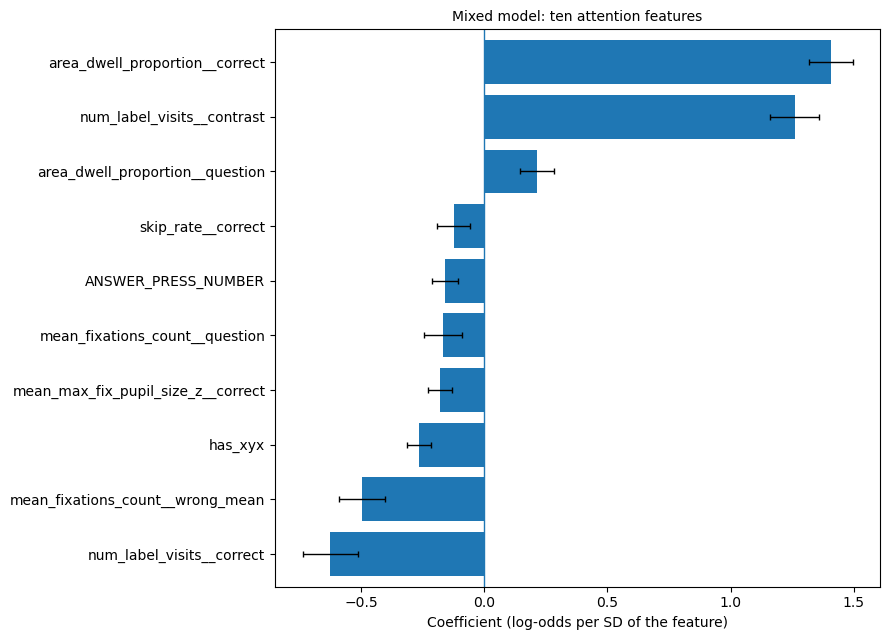

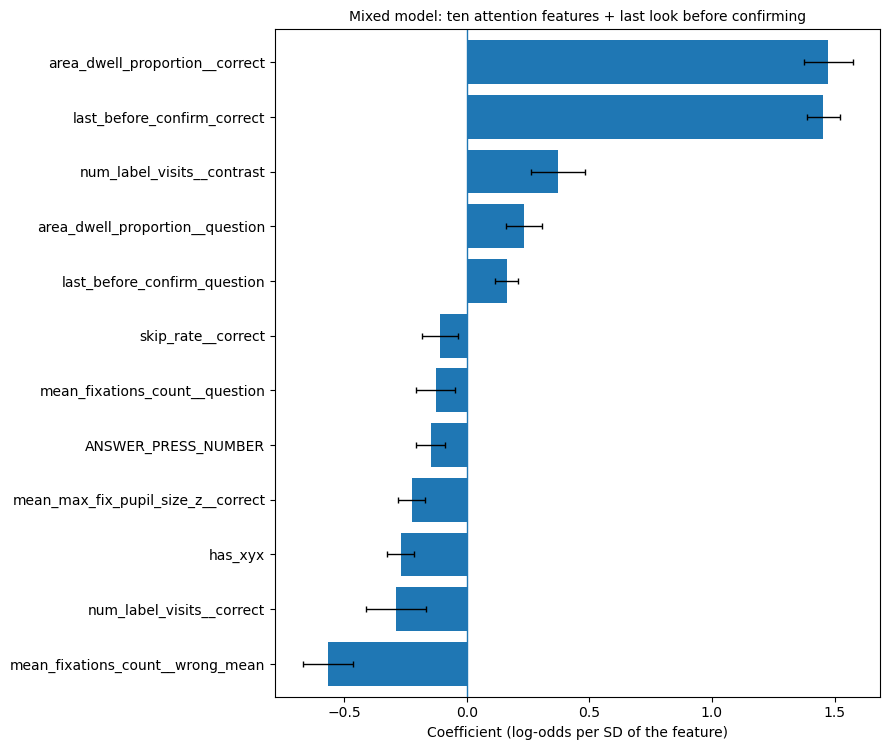

In [10]:
titles = {
    "select_1": "Mixed model: ten attention features",
    "select_1_plus_last_confirm": "Mixed model: ten attention features + last look before confirming",
}
for name, coef in coef_by_set.items():
    plot_coef_summary_barh(
        coef,
        significant_only=False,
        title=titles[name],
        xlabel="Coefficient (log-odds per SD of the feature)",
        ylabel="",
        save=False,
    )

### Against the logistic regression, and without the class weights
*`mixed_model.plots.plot_coefficient_comparison`*

The headline model's coefficients in three fits on the same trials: the logistic regression (with
participant-clustered Wald intervals, which are quick; the paper's bootstrap intervals are in its
notebook), the mixed model, and the same mixed model **without** the class weights, which is the
plain maximum-likelihood fit. The unweighted intercept differs by design; its slopes show what the
weights change.

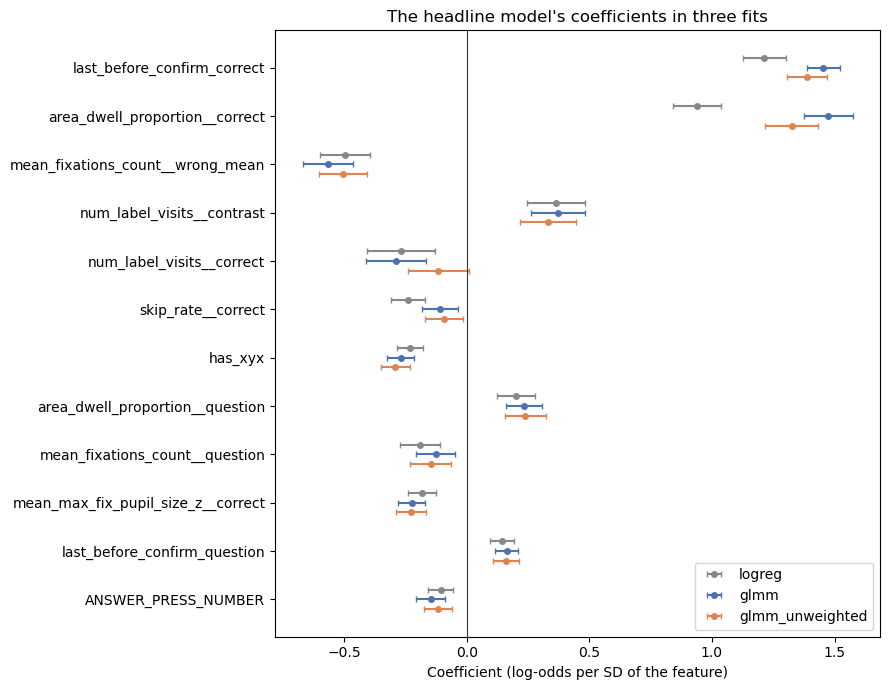

In [11]:
glmm_unweighted = TrialLevelJuliaGLMERModel(name="glmm_unweighted", class_weight=None)
glmm_unweighted.fit(trial_df, target_col=Con.IS_CORRECT_COLUMN, feature_cols=HEADLINE)

three_fits = {
    "logreg": collect_logreg_coef_summaries(
        trial_df, headline, ci_method="wald", ci_cluster="cluster",
    )["select_1_plus_last_confirm"],
    "glmm": coef_by_set["select_1_plus_last_confirm"],
    "glmm_unweighted": glmm_unweighted.get_coef_summary(),
}
plot_coefficient_comparison(
    three_fits,
    colors={"logreg": "#888888", "glmm": "#4C72B0", "glmm_unweighted": "#DD8452"},
    title="The headline model's coefficients in three fits",
    save=False,
)
plt.show()

### The random intercepts and how much they explain
*`mixed_model.run.run_glmm_fit_all`, `mixed_model.run.variance_summary`*

`run_glmm_fit_all` fits the headline mixed model on all trials and returns what only a mixed model
has: the random intercept of every participant and every item. They are in log-odds, shrunk towards
0, more so for levels with few trials.

The table below gives each grouping's standard deviation and its share of the variance on the latent
(log-odds) scale: its variance over both intercept variances plus pi²/3, the fixed variance of the
logistic distribution. This is the usual latent-scale intraclass correlation for a logistic model.
Read it from the unweighted fit; the class weights enlarge the variances.

Loading cached features from E:\Technion\QA PROJECT\programming\QA_eyetracking_workspace\data\datasets\l1_onestop\features\model_ready.csv


,class_weight,sd_participant,sd_item,share_participant,share_item,converged,singular
glmm (class-weighted),balanced,0.913403,1.614913,0.123929,0.387388,True,False
glmm_unweighted,None,0.739106,1.183485,0.104315,0.267461,True,False


,group_name,n_levels,mean,std,min,q25,median,q75,max,mean_abs,max_abs
0,participant_id,360,-0.0,0.738,-1.615,-0.508,0.016,0.501,2.002,0.593,2.002
1,text_id_with_q,972,-0.0,1.294,-4.396,-0.859,-0.005,1.018,3.576,1.051,4.396


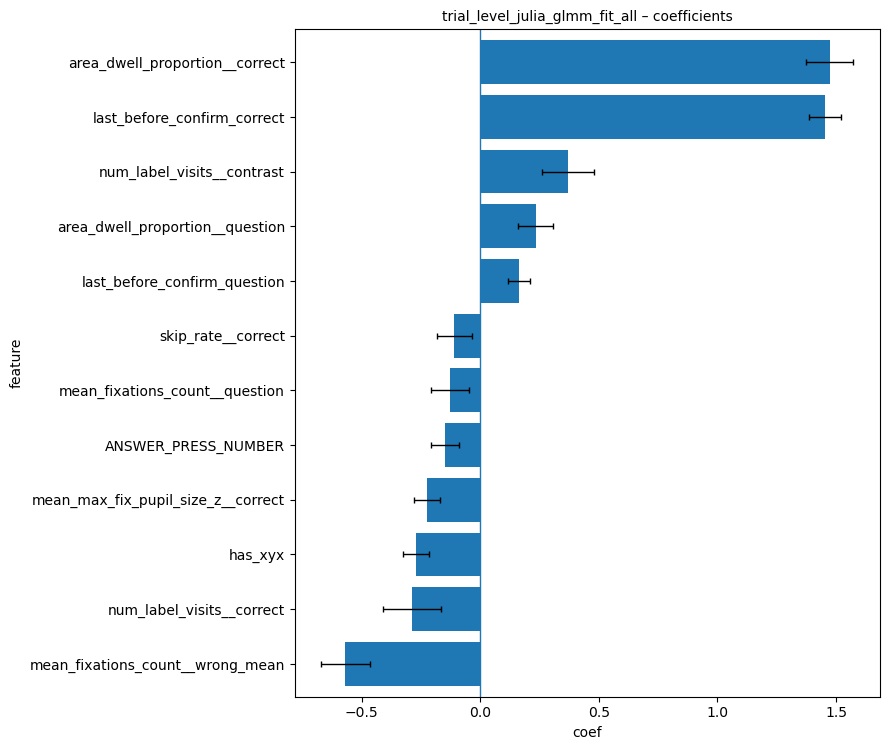

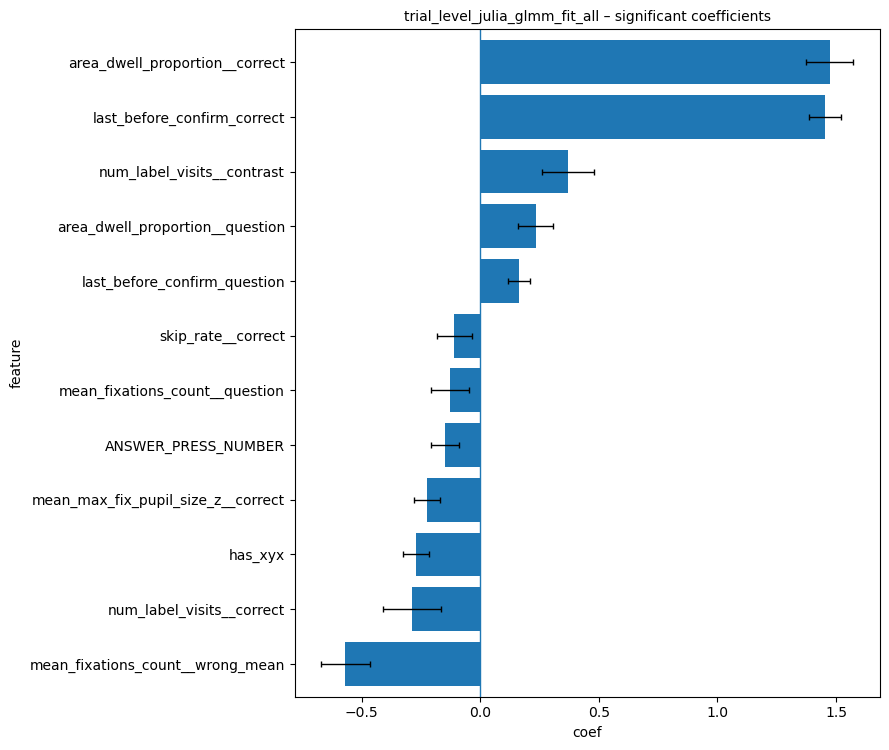

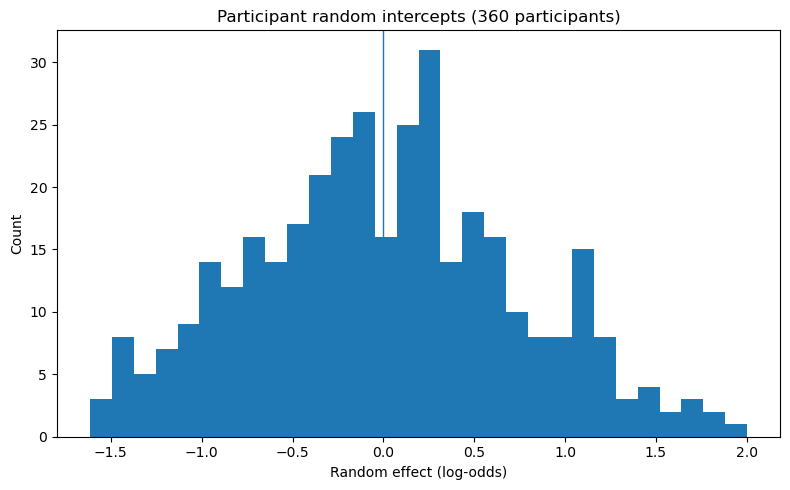

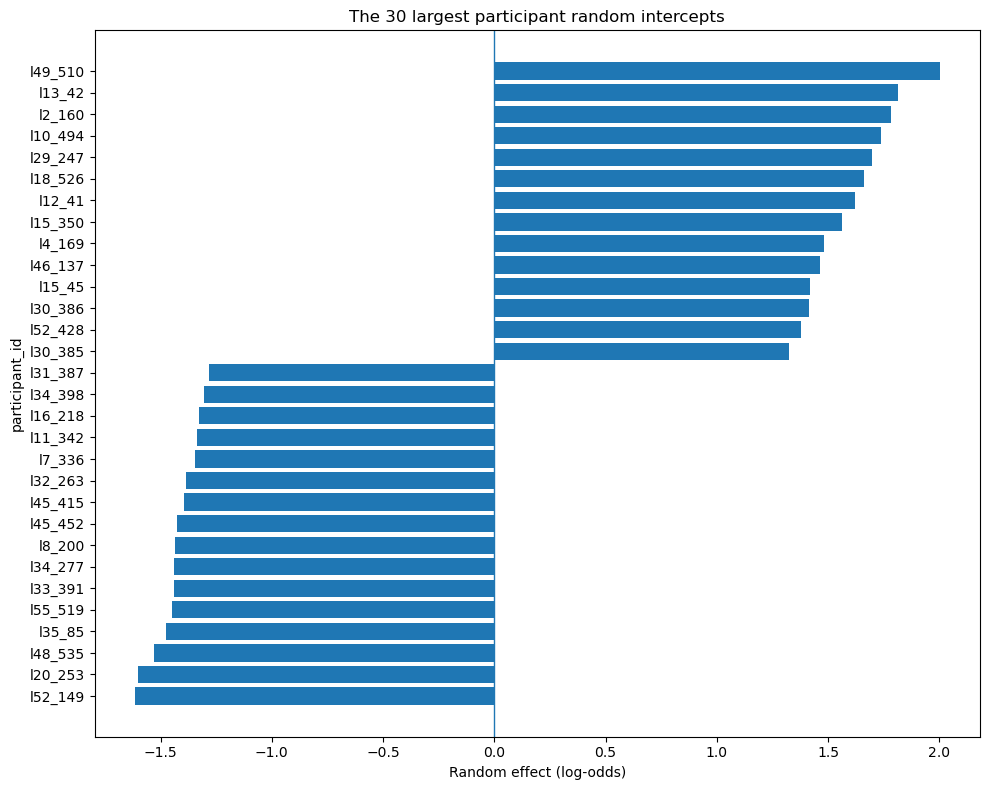

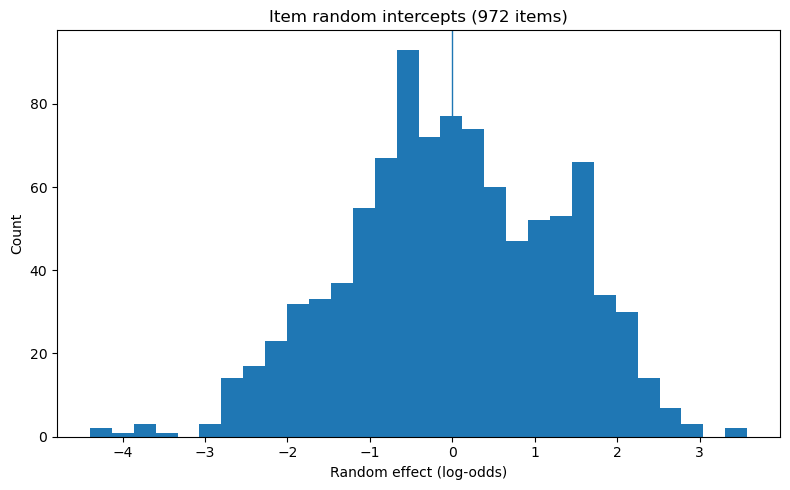

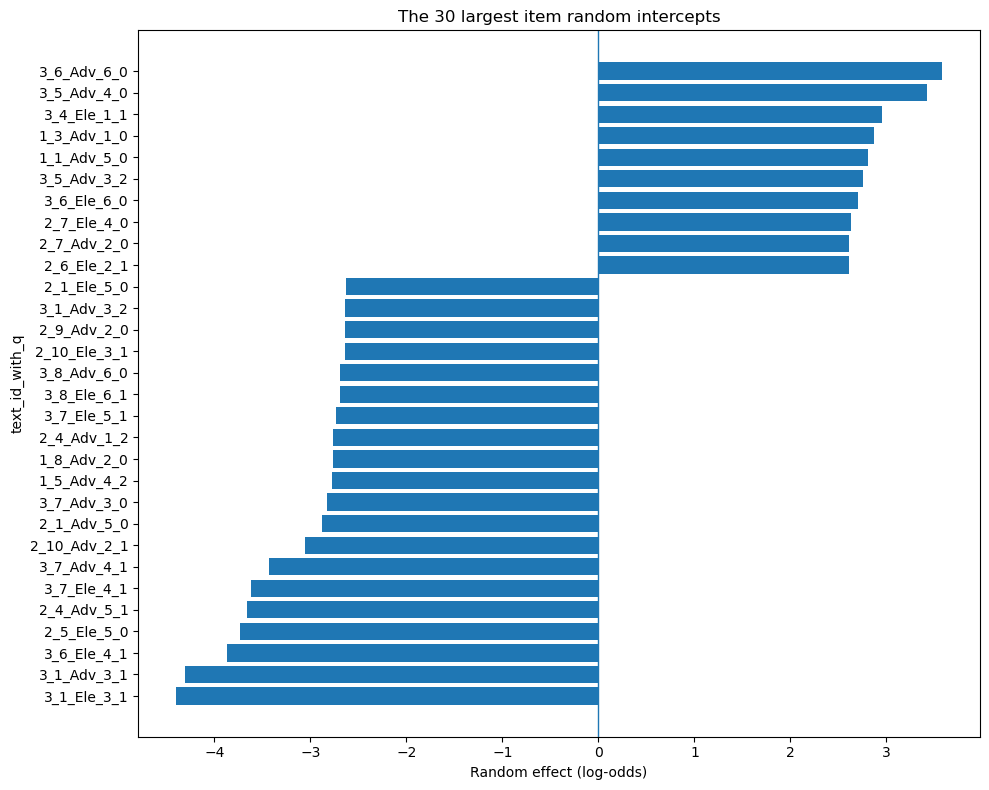

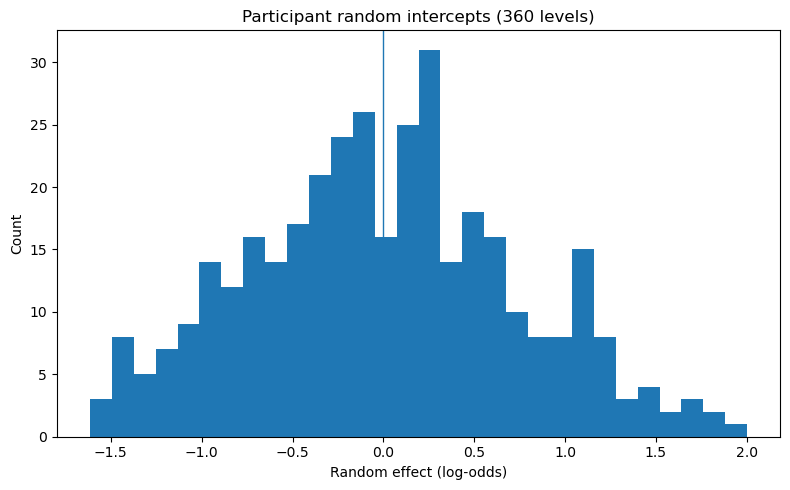

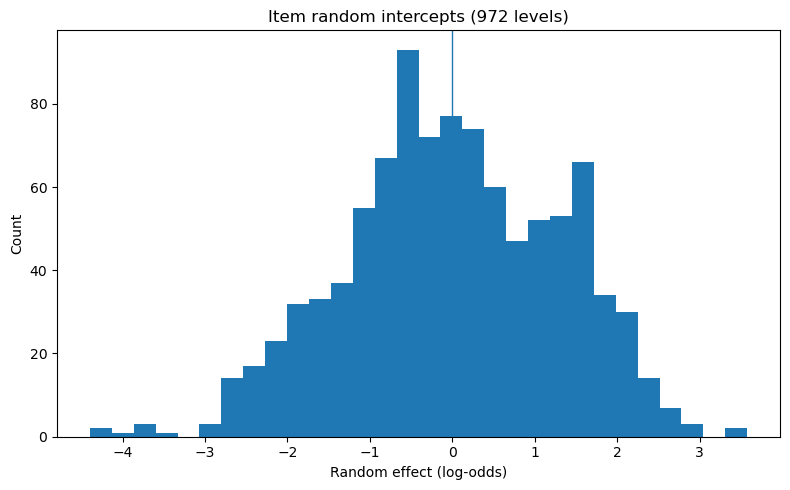

In [12]:
fit_all = run_glmm_fit_all(word_df, feature_cols=HEADLINE, save=False, close=True)  # its figures are redrawn below
display(variance_summary({"glmm (class-weighted)": fit_all["model"],
                          "glmm_unweighted": glmm_unweighted}))
display(fit_all["random_effects_summary_df"].round(3))

titles = {Con.PARTICIPANT_ID: "Participant random intercepts", TEXT: "Item random intercepts"}
for group, table in fit_all["random_effects"].items():
    plot_random_effects_distribution(table, title=f"{titles[group]} ({len(table)} levels)", save=False)
    plt.show()

## 4. One train/test split, to see what the model outputs
*`run.run_full_features_correctness_bundle`*

As in the logistic-regression notebook: the twelve-feature model fitted on fold 0's training trials
and scored on that fold's test trials of new participants reading new paragraphs. One split, not
the reported numbers. With both the participant and the item new, the two scorings are the same. It
prints the scores and draws the confusion matrix (as shares of each true outcome, and as counts),
the predicted probability of a correct answer split by what actually happened, and the coefficients
of this one fit, all and those whose interval excludes 0.

Loading cached features from E:\Technion\QA PROJECT\programming\QA_eyetracking_workspace\data\datasets\l1_onestop\features\model_ready.csv


MODEL: glmm_fixed
----------------------------------------------------------------------
Number of test trials: 720
Accuracy: 0.879
Balanced accuracy: 0.805
Positive (correct) trials: 625
Negative (incorrect) trials: 95

Precision / Recall / F1 (per class):
         precision  recall    f1  support
class_0      0.532   0.705 0.606       95
class_1      0.953   0.906 0.929      625

Averages:
  macro    P/R/F1: 0.742 / 0.805 / 0.767
  weighted P/R/F1: 0.897 / 0.879 / 0.886

ROC-AUC: 0.915
Average precision (PR-AUC): 0.986



Loading cached features from E:\Technion\QA PROJECT\programming\QA_eyetracking_workspace\data\datasets\l1_onestop\features\model_ready.csv


training trials: 11,711   held-out test trials: 720


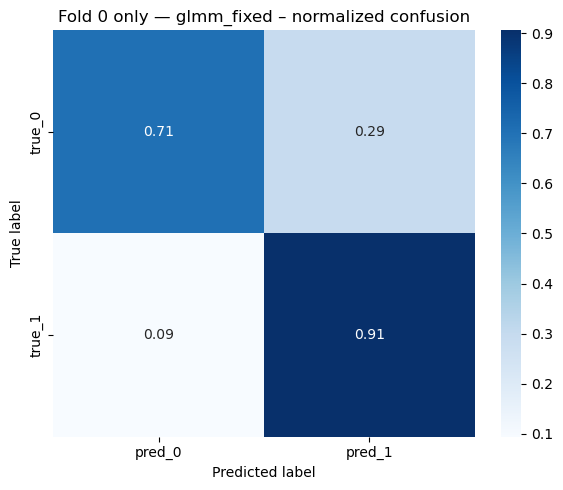

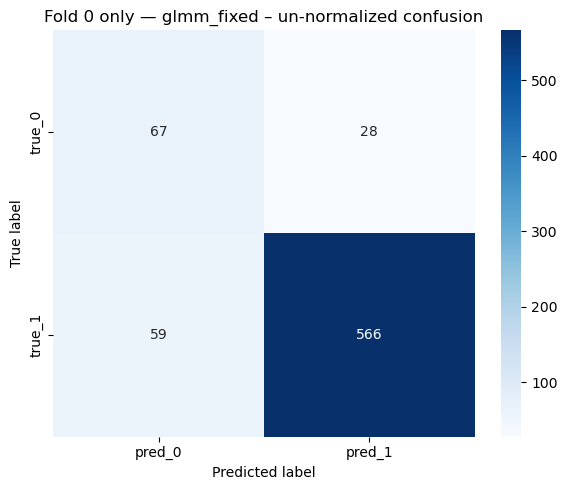

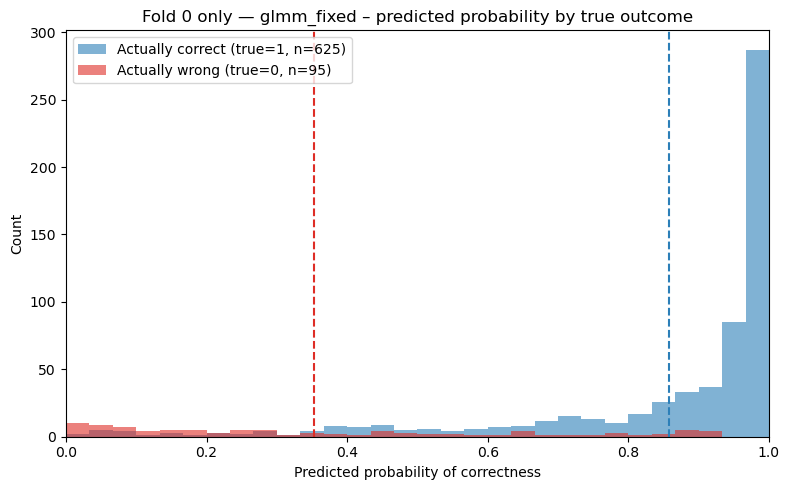

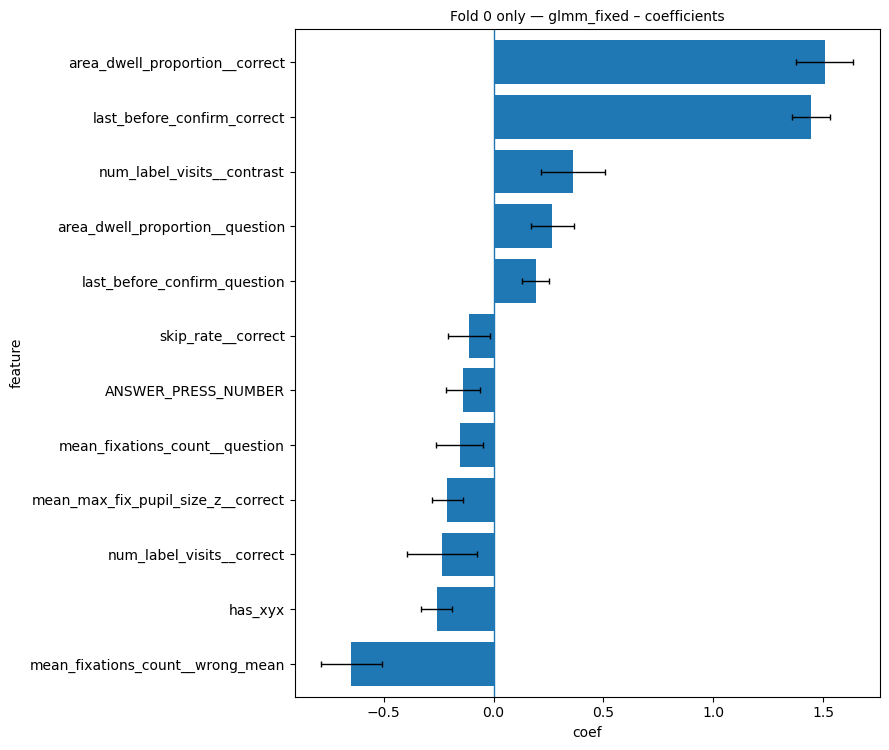

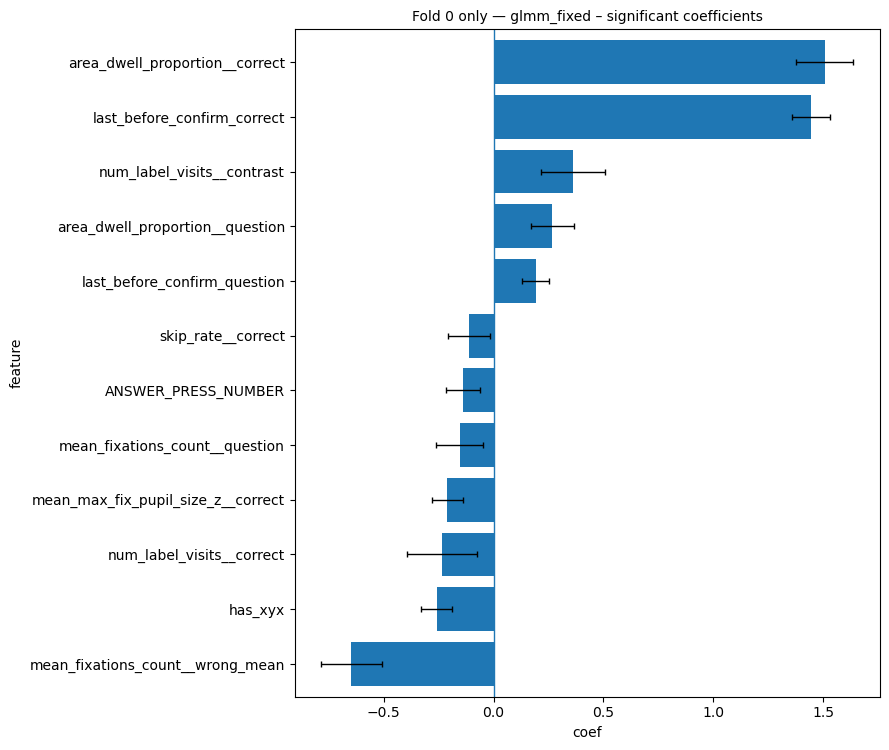

In [13]:
split = run_full_features_correctness_bundle(
    word_df,
    ["both"],                 # held out: new participants reading new paragraphs
    test_split="test",
    fold=0,
    feature_cols=HEADLINE,
    model_builder=glmm("fixed"),
    coef_ci_cluster="cluster",
    title_prefix="Fold 0 only",
    save=False,
)
# The bundle also draws the feature correlations, at 30 x 30 inches -- too large to read here.
# It is the last figure drawn; it is closed and redrawn at a readable size in section 5.
plt.close(plt.gcf())

print(f"training trials: {len(split['train_df']):,}   held-out test trials: {len(split['test_df']):,}")

**Where the two scorings differ.** The same fold, now scored on its test trials of *known*
participants reading new paragraphs. One fit, scored twice: with every random intercept at 0, and
with each participant's own intercept added. The second moves a trial's probability by how accurate
that person was in training. Whether that makes the probability a better stand-in for confidence,
or only a better guess of the person's accuracy, is the question this figure is for.

Loading cached features from E:\Technion\QA PROJECT\programming\QA_eyetracking_workspace\data\datasets\l1_onestop\features\model_ready.csv


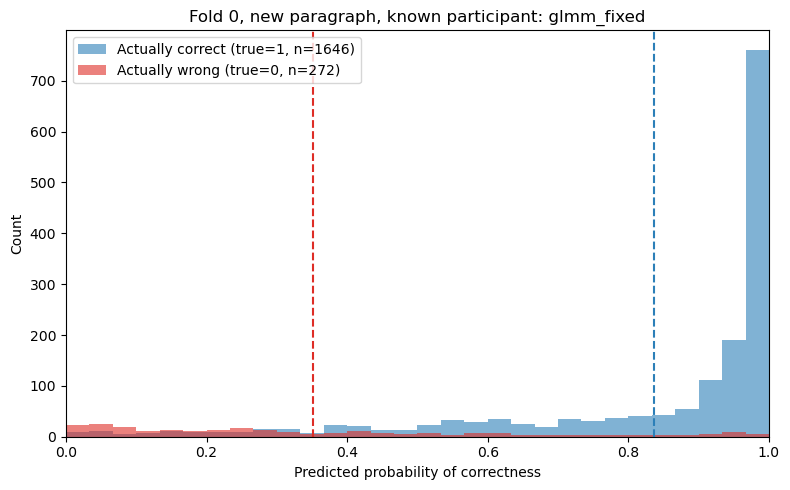

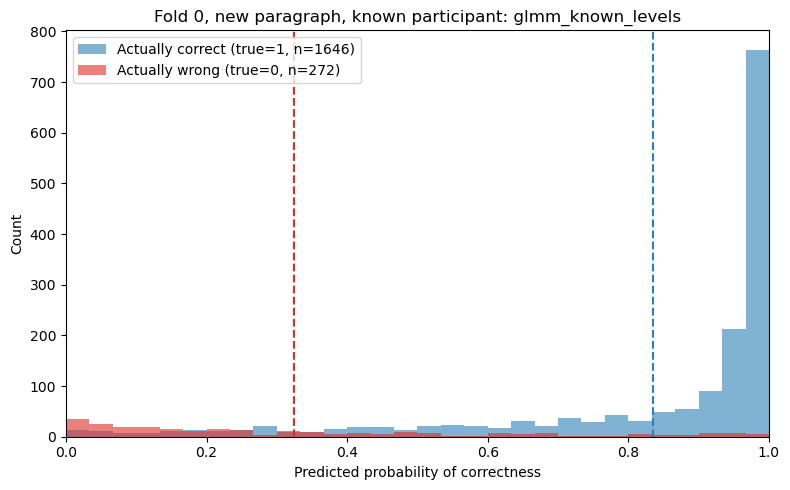

In [14]:
train_df, test_df, _ = build_train_test_trial_dfs(word_df, ["new_item"], test_split="test", fold=0)
model = TrialLevelJuliaGLMERModel(name="glmm")
model.fit(train_df, target_col=Con.IS_CORRECT_COLUMN, feature_cols=HEADLINE)

y_true = test_df[Con.IS_CORRECT_COLUMN].astype(int).to_numpy()
for predict_with in ["fixed", "known_levels"]:
    model.predict_with = predict_with
    plot_predicted_probability_hist(
        y_true, model.predict_proba(test_df),
        title=f"Fold 0, new paragraph, known participant: glmm_{predict_with}",
        save=False,
    )
    plt.show()

## 5. How the features correlate
*`plots.feature_ranks.plot_feature_correlation_heatmap`*

The same features as the logistic regression, so the same correlations (Pearson, with correlated
features placed next to each other, and missing pupil values filled with 0 as the model fills them).
Strongly correlated features share their effect, so their coefficients should be read together.

,skip_rate__correct,mean_max_fix_pupil_size_z__correct,area_dwell_proportion__correct,has_xyx,last_before_confirm_correct,num_label_visits__correct,num_label_visits__contrast,last_before_confirm_question,ANSWER_PRESS_NUMBER,mean_fixations_count__wrong_mean,area_dwell_proportion__question,mean_fixations_count__question
skip_rate__correct,1.00,-0.14,-0.26,-0.06,-0.10,-0.29,-0.19,0.02,-0.05,-0.33,-0.01,-0.14
mean_max_fix_pupil_size_z__correct,-0.14,1.00,0.10,0.04,0.07,0.22,0.15,-0.01,0.05,0.15,0.06,0.08
area_dwell_proportion__correct,-0.26,0.10,1.00,-0.00,0.27,-0.01,0.27,-0.04,-0.04,-0.35,-0.18,-0.19
has_xyx,-0.06,0.04,-0.00,1.00,0.09,0.29,0.25,-0.07,0.04,0.09,0.03,0.06
last_before_confirm_correct,-0.10,0.07,0.27,0.09,1.00,0.20,0.48,-0.19,-0.02,-0.15,-0.06,-0.08
num_label_visits__correct,-0.29,0.22,-0.01,0.29,0.20,1.00,0.71,-0.02,0.16,0.46,0.12,0.33
num_label_visits__contrast,-0.19,0.15,0.27,0.25,0.48,0.71,1.00,-0.03,0.03,-0.08,0.04,0.04
last_before_confirm_question,0.02,-0.01,-0.04,-0.07,-0.19,-0.02,-0.03,1.00,-0.01,-0.00,0.15,0.07
ANSWER_PRESS_NUMBER,-0.05,0.05,-0.04,0.04,-0.02,0.16,0.03,-0.01,1.00,0.17,0.03,0.11
mean_fixations_count__wrong_mean,-0.33,0.15,-0.35,0.09,-0.15,0.46,-0.08,-0.00,0.17,1.00,0.10,0.40


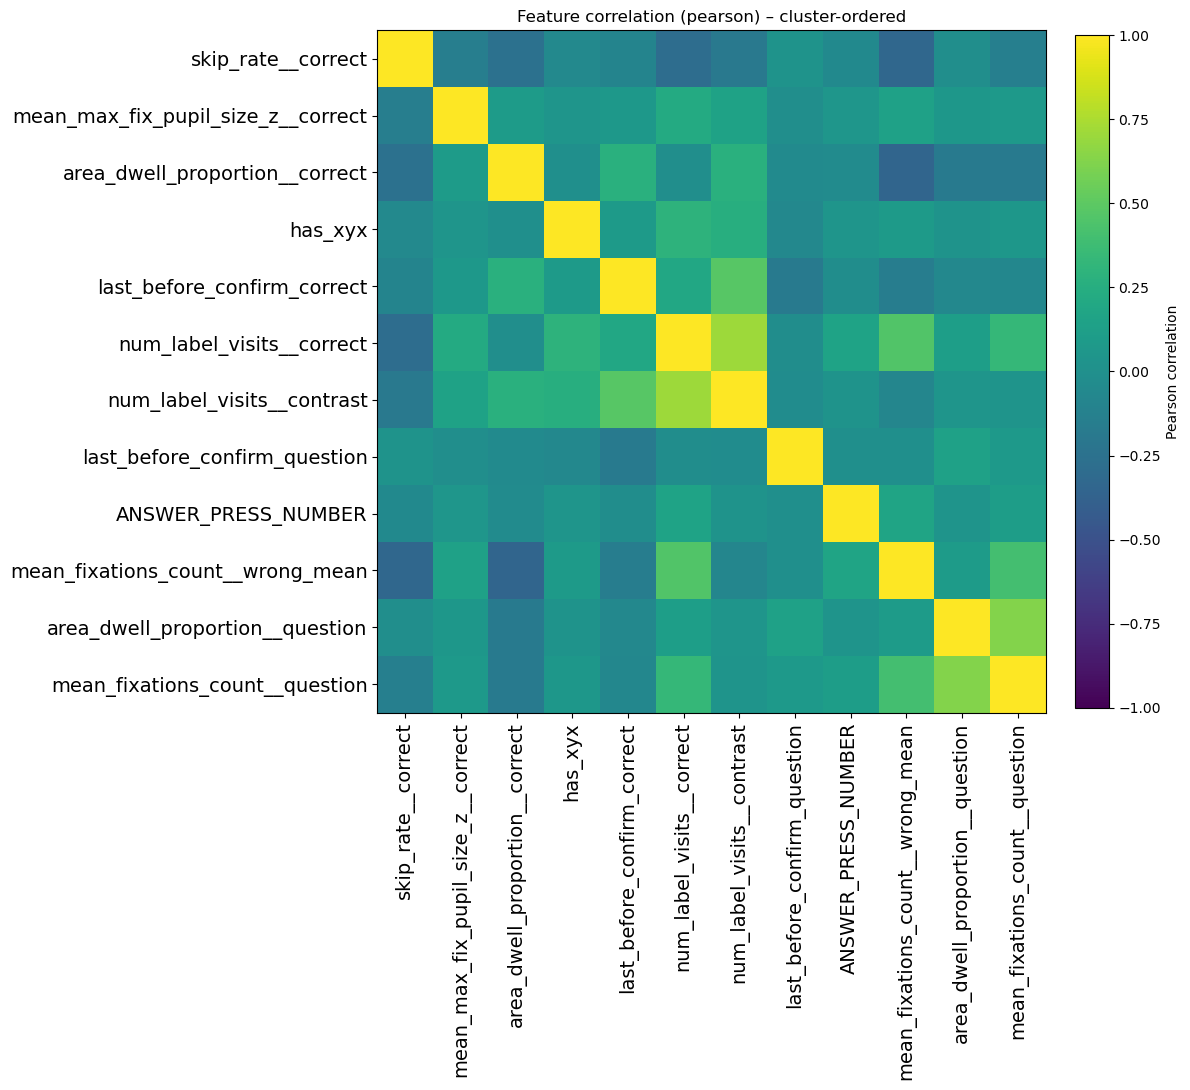

In [15]:
_, corr, _ = plot_feature_correlation_heatmap(
    trial_df,
    feature_cols=HEADLINE,
    method="pearson",
    cluster_order=True,
    figsize=(12, 11),
    save=False,
)
corr.round(2)